In [79]:
#imports

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Failed to reload module 'numpy._core._add_newdocs' from file 'c:\miniconda\Lib\site-packages\numpy\_core\_add_newdocs.py'
Traceback (most recent call last):
  File "c:\miniconda\Lib\site-packages\IPython\extensions\autoreload.py", line 326, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\miniconda\Lib\site-packages\IPython\extensions\autoreload.py", line 580, in superreload
    module = reload(module)
  File "c:\miniconda\Lib\importlib\__init__.py", line 129, in reload
    _bootstrap._exec(spec, module)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 869, in _exec
  File "<frozen importlib._bootstrap_external>", line 759, in exec_module
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
  File "c:\miniconda\Lib\site-packages\numpy\_core\_add_newdocs.py", line 7064, in <module>
    add_newdoc('numpy.dtypes', _dtype_name,
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  

In [80]:
#recherche de données

local_file="data/fremont.csv"
URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)
    print(req.status_code)

    with open(local_file, 'w') as writer:
        writer.write(req.text)

data=pd.read_csv(local_file)
data.shape
data.head()

le fichier data/fremont.csv est déjà là


RecursionError: Stack overflow (used 1952 kB)

RecursionError: Stack overflow (used 1952 kB)

In [ ]:
data.drop_duplicates(inplace=True )

In [ ]:
sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

print(type(sample_dates))
print(sample_dates.date)
print(sample_dates.time)
print(sample_dates.day_of_week)

#pour ne garder que les dates postérieures au 20 janvier 2024
sample_dates[(sample_dates > "2024/01/20 00:00:00")]

#pour ne garder que les dates de janvier 2024
sample_dates[(sample_dates.month == 1 )]

data.index=pd.to_datetime(data.Date,format="%m/%d/%Y %I:%M:%S %p")

del data["Date"]

<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)]
[datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)]
Index([0, 5, 5], dtype='int32')


Echauffement:

1/ sample_dates est de type DatetimeIndex

2/ .date renvoie les dates, .time les heures et minutes et .day_of_week renvoie les jours de la semaine avec un code lundi=0,mardi=1,...,dimanche=6.

3/Il faut utiliser de slicing avec un boleen en condition (voir dans cellule code au dessus)

4/Idem

In [ ]:
#renommage des colonnes
data.columns= ["Total","West","East"]
print(data.head())

                     Total  West  East
Date                                  
2022-08-01 00:00:00   23.0   7.0  16.0
2022-08-01 01:00:00   12.0   5.0   7.0
2022-08-01 02:00:00    3.0   0.0   3.0
2022-08-01 03:00:00    5.0   2.0   3.0
2022-08-01 04:00:00   10.0   2.0   8.0


In [ ]:
#Données manquantes

print("Nombre de lignes avec une valeur manquante")
print(data[data.isna().any(axis=1)].shape)

#Conversions 
data=data.convert_dtypes(convert_integer=True)

print(data.dtypes)

Nombre de lignes avec une valeur manquante
(14, 3)
Total    Int64
West     Int64
East     Int64
dtype: object


<Axes: xlabel='Date'>

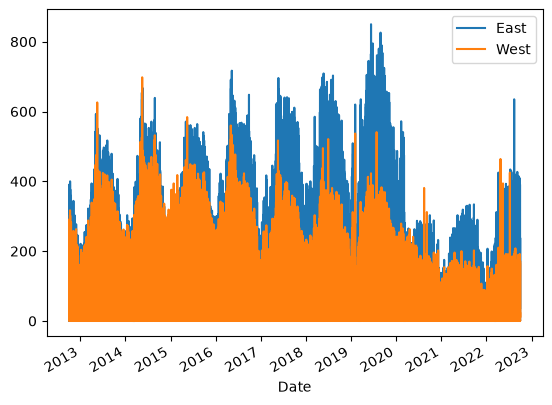

In [ ]:
#A quoi ça ressemble

# un premier jet, pas terrible du tout
data[['East', 'West']].plot()


(522, 3)


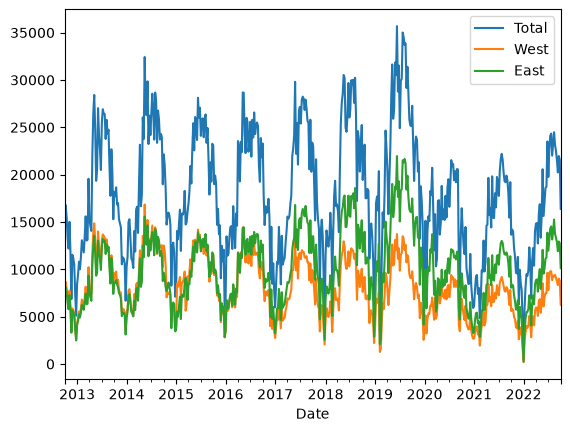

In [ ]:
#resampling temporel

(data.resample("1W").sum()).plot()
print((data.resample("1W").sum()).shape[0])

#on a bien 87000~522*24*7

In [ ]:
#découpage temporel

data1=data[data.index.year<=2017]

(0.0, 1100000.0)

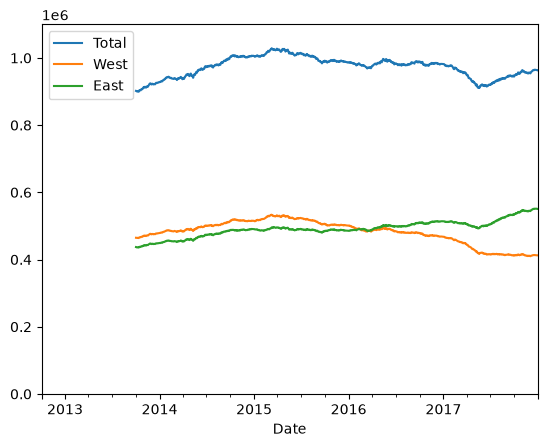

In [ ]:
#évolution annuelle

annuelle=((data1.resample("1D").sum()).rolling(365)).sum()
annuelle.plot()
plt.ylim(0,1.1e6)

<Axes: xlabel='time'>

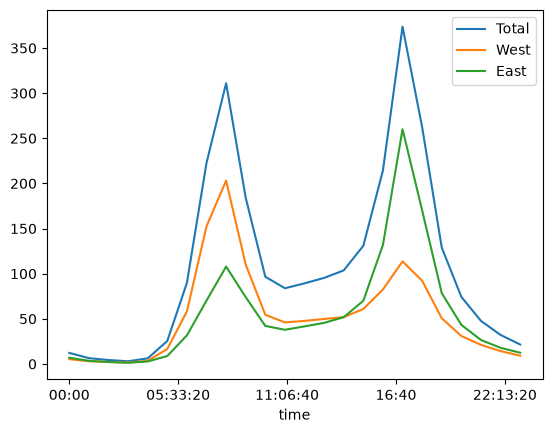

In [ ]:
#profil journalier moyen

(data1.groupby(data1.index.time).mean()).plot()

In [ ]:
#une courbe par jour

